# Person Re-ID with identity-conditioned latent forecasting

**Research question.** Does supplying a candidate query identity make the observed continuation of a different-camera gallery tracklet more predictable? A tracklet is a time-ordered sequence of cropped detections from one camera.

The query contains a short prefix. Each archived gallery clip contains a prefix and a later sequence. A recurrent model rolls a gallery state forward without seeing its later frames. Run the same model with a query donor and with an empty donor, then measure how much the query improves the likelihood of the gallery continuation. The retrieval baseline uses cosine similarity on the pooled query prefix and the same gallery frames. MARS supplies the evaluation data. The artificial data in `smoke` exercises the notebook.

## Run on Kaggle

1. Open a Kaggle notebook and use **File → Import Notebook** to load this file. Leave `RUN_PROFILE = "smoke"` and use **Run All** for a CPU check. This mode needs no data attachment or internet.
2. For real data, get the [MARS dataset](https://zheng-lab-anu.github.io/Project/project_mars.html) and its five [official annotation files](https://github.com/liangzheng06/MARS-evaluation/tree/master/info). The original image package is 6.26 GB. Attach the two crop directories or their individual ZIP files using **Add Input**. Unpack a single outer download archive once if needed. The notebook reads individual crop archives directly.
3. In Settings choose a **GPU** accelerator, such as a T4. Set `RUN_PROFILE = "pilot"`, then run from the first cell. When the pilot finishes, switch to `"research"` for the full original MARS test query/gallery protocol. The training identities reserve a fixed validation split.
4. If auto-discovery needs a hint, set `MARS_ROOT` to the directory containing both crop inputs. Set `INFO_DIR` to the folder containing the five files if the annotations are attached separately. The output folder is printed in Cell 1.

```text
MARS/
  bbox_train/ or bbox_train.zip
  bbox_test/  or bbox_test.zip
  info/
    train_name.txt
    test_name.txt
    tracks_train_info.mat
    tracks_test_info.mat
    query_IDX.mat
```

The notebook uses Kaggle's PyTorch, NumPy, SciPy, Pandas, Matplotlib and Pillow. It trains a compact shared encoder from scratch. Kaggle Internet can stay off once MARS is attached.


## 2026 literature and the proposed experiment

| Reference | What it tested |
| --- | --- |
| [Ge et al., CSCI-VJEPA, IEEE BigDIA 2026](https://doi.org/10.1109/BigDIA71496.2026.11684540) | Fuses frozen V-JEPA 2.1 video tokens with RGB in a clothes-changing Re-ID system. On the MEVID clothes-changing subset the paper reports 21.4% mAP and 49.3% Rank-10 versus 21.2% and 37.3% for its CSCI-V baseline. |
| [Wei, Sun and Zhao, Human-JEPA, 2026 arXiv preprint](https://arxiv.org/abs/2608.21160) | Adapts a video encoder by forecasting future latents and evaluates a frozen image Re-ID probe on Market-1501. Table 2 reports 46.35% mAP versus 43.70% for its V-JEPA 2.1 base. |
| [Wu et al., ReWorld-Track, 2026 arXiv preprint](https://arxiv.org/abs/2609.36677) | Uses a recursive event world model to preserve pedestrian identity across camera handoffs. On MTMMC the structured update reaches 87.41% next-camera accuracy versus 86.03% for a generic updater. Its benchmarks evaluate online tracking and event prediction. |

CSCI-VJEPA and Human-JEPA use predictive learning to improve the representation. ReWorld-Track forecasts the target's next camera and arrival time for online association. This experiment forecasts the change inside the same archived gallery clip twice, with and without query information, and uses the gain as a **pairwise retrieval score**. Training pairs a same-identity donor from a second camera with an appearance-hard, different-identity donor from that camera. This keeps the gallery prefix and camera fixed when comparing donors. The use of the continuation is retrospective because the gallery footage already exists.

The experiment isolates three claims. The ordered forecast should beat appearance pooling. It should also beat the same predictor trained on permuted suffixes, which contain the same frames in a different order. Finally, the right donor should predict the future better than a camera-matched wrong donor. These are hypotheses to test. The MARS experiment measures cross-camera retrieval and sensitivity to simulated crop occlusion.


In [1]:
# Cell 1. Imports and run configuration
import io
import json
import math
import os
import random
import time
import zipfile
from collections import defaultdict, deque
from dataclasses import asdict, dataclass
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from PIL import Image, ImageDraw
from scipy.io import loadmat
from torch.utils.data import DataLoader, Dataset, Sampler

RUN_PROFILE = "smoke"  # "smoke", "pilot", or "research"
MARS_ROOT = ""         # e.g. "/kaggle/input/datasets/owner/mars/MARS"
INFO_DIR = ""          # Optional separate folder containing the five annotation files
SEED = 42
SPLIT_SEED = 1729
NUM_WORKERS = 0        # Consider 2 with extracted crop folders if more I/O is needed.

@dataclass(frozen=True)
class Settings:
    height: int
    width: int
    embed_dim: int
    hidden_dim: int
    encoder_width: int
    identities_per_batch: int
    frame_epochs: int
    world_epochs: int
    max_steps: int | None
    train_id_limit: int | None
    test_id_limit: int | None
    train_tracks_per_camera: int | None
    extract_batch: int
    shortlist: int
    bootstrap_samples: int
    context: int = 4
    horizon: int = 3
    stride: int = 2
    swap_margin: float = 0.10
    swap_weight: float = 0.75
    occlusion_probability: float = 0.35

PROFILES = {
    "smoke": Settings(48, 24, 32, 48, 12, 4, 3, 5, 7, None, None, None, 16, 16, 300),
    "pilot": Settings(96, 48, 64, 96, 24, 8, 6, 10, 70, 100, 64, 3, 24, 50, 800),
    "research": Settings(128, 64, 96, 128, 24, 12, 20, 24, None, None, None, None, 24, 100, 2000),
}

if RUN_PROFILE not in PROFILES:
    raise ValueError(f"RUN_PROFILE must be one of {', '.join(PROFILES)}.")
cfg = PROFILES[RUN_PROFILE]
n_frames = cfg.context + cfg.horizon
device = torch.device("cpu")
if torch.cuda.is_available():
    try:
        torch.ones(1, device="cuda").sum().item()
    except RuntimeError as error:
        print(f"CUDA check failed. Falling back to CPU. Details: {error}")
    else:
        device = torch.device("cuda")
use_amp = device.type == "cuda"
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.set_float32_matmul_precision("highest")
torch.backends.cudnn.benchmark = False

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if use_amp:
        torch.cuda.manual_seed_all(seed)

seed_all(SEED)
base_out = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()
default_out = base_out / "identity_forecast_reid" / RUN_PROFILE / f"seed_{SEED}"
out_dir = Path(os.environ.get("REID_OUTPUT_DIR", str(default_out))).expanduser().resolve()
out_dir.mkdir(parents=True, exist_ok=True)

print(f"Profile {RUN_PROFILE} | {device} | PyTorch {torch.__version__}")
print(f"Output directory: {out_dir}")
if RUN_PROFILE != "smoke" and not use_amp:
    print("Real-data training is running on CPU. Choose a Kaggle GPU to accelerate it.")


Profile smoke | cuda | PyTorch 2.11.0+cu130
Output directory: /kaggle/working/identity_forecast_reid/smoke/seed_42


In [2]:
# Cell 2. Read official MARS metadata and build identity-disjoint splits
@dataclass(frozen=True)
class Tracklet:
    split: str
    row: int
    pid: int
    cam: int
    frames: tuple

    @property
    def key(self):
        return f"{self.split}-{self.row:06d}"

INFO_FILES = (
    "train_name.txt", "test_name.txt", "tracks_train_info.mat",
    "tracks_test_info.mat", "query_IDX.mat",
)

def split_input(root, split):
    folder = root / f"bbox_{split}"
    archive = root / f"bbox_{split}.zip"
    if folder.is_dir():
        nested = folder / folder.name
        return nested if nested.is_dir() else folder
    if archive.is_file():
        return archive
    raise FileNotFoundError(f"Missing {folder.name}/ or {archive.name} in {root}")

def is_mars_root(path, info_override):
    info = info_override or path / "info"
    if not all((info / name).is_file() for name in INFO_FILES):
        return False
    return all(
        (path / f"bbox_{split}").is_dir() or (path / f"bbox_{split}.zip").is_file()
        for split in ("train", "test")
    )

def find_mars_root(explicit, info_override):
    if explicit:
        root = Path(explicit).expanduser()
        if is_mars_root(root, info_override):
            return root
        raise FileNotFoundError(f"{root} is missing one or more inputs in the setup diagram.")
    pending = deque([(Path("/kaggle/input"), 0)])
    matches = []
    while pending:
        candidate, depth = pending.popleft()
        if not candidate.is_dir():
            continue
        if is_mars_root(candidate, info_override):
            matches.append(candidate)
            continue
        if depth < 5:
            pending.extend(
                (child, depth + 1) for child in sorted(candidate.iterdir())
                if child.is_dir() and child.name not in {"bbox_train", "bbox_test", "info"}
            )
    if len(matches) == 1:
        return matches[0]
    detail = ", ".join(str(path) for path in matches) or "no matching folder"
    raise FileNotFoundError(f"MARS auto-discovery found {detail}. Check the layout and set MARS_ROOT.")

def read_mat_integer(path, key):
    arrays = loadmat(path, variable_names=[key])
    if key not in arrays:
        raise ValueError(f"{path.name} does not contain '{key}'.")
    data = arrays[key]
    if not np.isfinite(data).all() or not np.equal(data, np.rint(data)).all():
        raise ValueError(f"{path.name} contains non-integer or non-finite values.")
    return data.astype(np.int64)

def read_mars_tracks(info, split):
    name_file = info / f"{split}_name.txt"
    names = [line.strip() for line in name_file.read_text(encoding="utf-8-sig").splitlines()]
    rows = read_mat_integer(info / f"tracks_{split}_info.mat", f"track_{split}_info")
    if rows.ndim != 2 or rows.shape[1] != 4:
        raise ValueError(f"Expected four columns in the official {split} tracklet table.")
    tracks = []
    for row, (first, last, pid, cam) in enumerate(rows):
        if not 1 <= first <= last <= len(names) or not 1 <= cam <= 6:
            raise ValueError(f"Invalid MARS frame bounds or camera in {split} row {row + 1}.")
        filenames = tuple(names[first - 1:last])
        if any(not name or "/" in name or "\\" in name for name in filenames):
            raise ValueError(f"Expected crop filenames in {split} row {row + 1}.")
        tracks.append(Tracklet(split, row, int(pid), int(cam - 1), filenames))
    return tracks

def synthetic_tracks(split, pids, seed):
    rng = np.random.default_rng(seed)
    tracks = []
    for pid in pids:
        for cam in range(3):
            for repeat in range(2):
                row = len(tracks)
                length = int(rng.integers(14, 23)) if repeat == 0 else int(rng.integers(4, 23))
                tracks.append(Tracklet(split, row, pid, cam, tuple(range(length))))
    return tracks

def group_by_identity_and_camera(tracks):
    groups = defaultdict(lambda: defaultdict(list))
    for index, track in enumerate(tracks):
        if track.pid > 0:
            groups[track.pid][track.cam].append(index)
    return {pid: dict(by_cam) for pid, by_cam in groups.items()}

def choose_ids(pids, count, rng):
    pids = sorted(pids)
    if count is None or len(pids) <= count:
        return set(pids)
    return set(rng.choice(pids, count, replace=False).tolist())

def make_val_queries(tracks):
    groups = group_by_identity_and_camera(tracks)
    return [
        tracks[indices[0]]
        for by_camera in groups.values() if len(by_camera) > 1
        for indices in by_camera.values()
    ]

def limit_train_tracks(tracks, limit, rng):
    if limit is None:
        return tracks
    keep = []
    for by_camera in group_by_identity_and_camera(tracks).values():
        for indices in by_camera.values():
            selected = rng.choice(indices, min(limit, len(indices)), replace=False)
            keep.extend(selected.tolist())
    return [tracks[index] for index in sorted(keep)]


rng = np.random.default_rng(SPLIT_SEED)
source_paths = {}
info_path = None
if RUN_PROFILE == "smoke":
    train_original = synthetic_tracks("train", range(1, 17), SPLIT_SEED)
    test_original = synthetic_tracks("test", range(101, 111), SPLIT_SEED + 1)
    # A second query camera creates multiple correlated queries per synthetic identity.
    official_query = [track for track in test_original if track.cam < 2 and track.row % 2 == 0]
    camera_count = 3
else:
    info_override = Path(INFO_DIR).expanduser() if INFO_DIR else None
    if info_override and not all((info_override / name).is_file() for name in INFO_FILES):
        raise FileNotFoundError(f"Missing one or more MARS annotations in {info_override}.")
    root = find_mars_root(MARS_ROOT, info_override)
    info_path = info_override or root / "info"
    source_paths = {split: split_input(root, split) for split in ("train", "test")}
    train_original = read_mars_tracks(info_path, "train")
    test_original = read_mars_tracks(info_path, "test")
    query_rows = read_mat_integer(info_path / "query_IDX.mat", "query_IDX").ravel() - 1
    if len(query_rows) == 0 or query_rows.min() < 0 or query_rows.max() >= len(test_original):
        raise ValueError("Official query indices are absent or outside the test tracklet table.")
    if len(np.unique(query_rows)) != len(query_rows):
        raise ValueError("Official query indices contain duplicates.")
    if any(test_original[row].pid <= 0 for row in query_rows):
        raise ValueError("Expected only positive identities in the official query indices.")
    official_query = [test_original[row] for row in query_rows]
    camera_count = 6
    print(f"Crop inputs: {root} | annotations: {info_path}")

eligible = {
    pid for pid, by_cam in group_by_identity_and_camera(train_original).items()
    if len(by_cam) >= 2
}
if len(eligible) < 4:
    raise ValueError("At least four training identities need tracklets in two or more cameras.")

val_n = min(max(4, round(0.12 * len(eligible))), len(eligible) - 2)
val_ids = choose_ids(eligible, val_n, rng)
train_ids = choose_ids(eligible - val_ids, cfg.train_id_limit, rng)
train_tracks = limit_train_tracks(
    [track for track in train_original if track.pid in train_ids],
    cfg.train_tracks_per_camera,
    rng,
)
val_gallery = [track for track in train_original if track.pid in val_ids]
val_query = make_val_queries(val_gallery)

test_pids = choose_ids({track.pid for track in official_query}, cfg.test_id_limit, rng)
if cfg.test_id_limit is None:
    test_gallery = [track for track in test_original if track.pid >= 0]
else:
    distractor_rows = [track.row for track in test_original if track.pid == 0]
    keep_rows = set(rng.choice(distractor_rows, min(320, len(distractor_rows)), replace=False).tolist())
    test_gallery = [
        track for track in test_original
        if track.pid in test_pids or (track.pid == 0 and track.row in keep_rows)
    ]
test_query = [track for track in official_query if track.pid in test_pids]
test_all_ids = {track.pid for track in test_gallery if track.pid > 0}

if train_ids & val_ids or (train_ids | val_ids) & test_all_ids:
    raise ValueError("An identity is shared by train, validation, or test. Check the annotations.")
if not all((train_tracks, val_query, val_gallery, test_query, test_gallery)):
    raise ValueError("An empty training, validation, or test partition was found.")

class_to_index = {pid: index for index, pid in enumerate(sorted(train_ids))}
split_info = {
    "train": len(train_tracks), "val_query": len(val_query), "val_gallery": len(val_gallery),
    "test_query": len(test_query), "test_gallery": len(test_gallery),
    "test_distractors": sum(track.pid == 0 for track in test_gallery),
}
protocol = {
    "smoke": "Artificial tracklets",
    "pilot": "Subset of the official MARS split",
    "research": "Official query indices and all non-junk test tracklets as gallery",
}[RUN_PROFILE]
display(pd.Series(split_info, name="Tracklets").to_frame())
print(protocol)


,Tracklets
train,72
val_query,12
val_gallery,24
test_query,20
test_gallery,60
test_distractors,0


Artificial tracklets


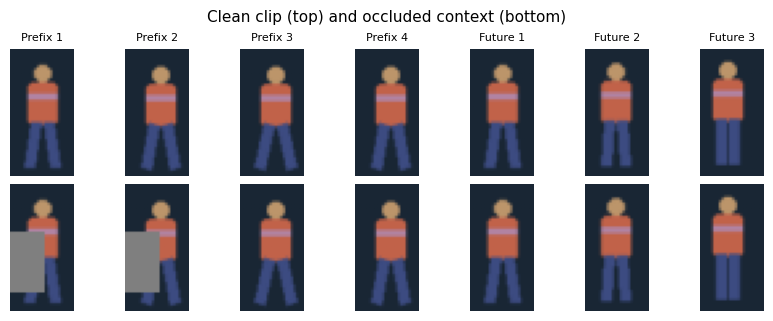

In [3]:
# Cell 3. Read and preview time-ordered crops and simulated query occlusion
class FrameReader:
    def __init__(self, paths):
        self.paths = paths
        self._process = None
        self._archives = {}
        self._prefixes = {}

    def close(self):
        for handle in self._archives.values():
            handle.close()
        self._archives.clear()
        self._prefixes.clear()

    def _read_from_zip(self, path, relative):
        if os.getpid() != self._process:
            self.close()
            self._process = os.getpid()
        if path not in self._archives:
            handle = zipfile.ZipFile(path)
            self._archives[path] = handle
            sample = next(
                (entry.filename for entry in handle.filelist
                 if entry.filename.lower().endswith((".jpg", ".jpeg"))
                 and not entry.filename.startswith("__MACOSX/")),
                None,
            )
            if sample is None:
                raise ValueError(f"{path.name} contains no JPEG crops.")
            head, _, filename = sample.rpartition("/")
            prefix, _, pid_dir = head.rpartition("/")
            if pid_dir != filename[:4]:
                raise ValueError(f"Unexpected crop path in {path.name}: {sample}")
            self._prefixes[path] = prefix + "/" if prefix else ""
        handle = self._archives[path]
        return handle.read(self._prefixes[path] + relative)

    def read(self, track, frame_index):
        frame = track.frames[frame_index]
        if not self.paths:
            return self.synthetic_image(track, int(frame))
        folder = self.paths[track.split]
        relative = f"{frame[:4]}/{frame}"
        try:
            if folder.is_dir():
                with Image.open(folder / relative) as image:
                    return image.convert("RGB")
            with Image.open(io.BytesIO(self._read_from_zip(folder, relative))) as image:
                return image.convert("RGB")
        except (KeyError, OSError, zipfile.BadZipFile) as error:
            raise RuntimeError(f"Could not read {relative} from {folder} for {track.key}.") from error

    @staticmethod
    def synthetic_image(track, frame):
        rng = np.random.default_rng(track.pid)
        shirt = tuple(rng.integers(55, 220, 3).tolist())
        trousers = tuple(rng.integers(20, 155, 3).tolist())
        stripe = tuple(rng.integers(120, 248, 3).tolist())
        background = [(25, 38, 52), (58, 42, 32), (31, 53, 40)][track.cam]
        image = Image.new("RGB", (40, 80), background)
        draw = ImageDraw.Draw(image)
        wave = math.sin((frame + track.row * 0.27) * (0.22 + 0.03 * (track.pid % 5)))
        x = 20 + round(3 * wave) + track.cam - 1
        y = 9 + round(2 * wave)
        draw.ellipse((x - 5, y, x + 5, y + 10), fill=(188, 149, 106))
        draw.rounded_rectangle((x - 9, y + 11, x + 9, y + 37), 3, fill=shirt)
        draw.rectangle((x - 9, y + 16 + track.pid % 6, x + 9, y + 19 + track.pid % 6), fill=stripe)
        leg = round(4 * wave)
        draw.line((x - 4, y + 36, x - 6 - leg, y + 64), fill=trousers, width=7)
        draw.line((x + 4, y + 36, x + 6 + leg, y + 64), fill=trousers, width=7)
        return image

def sampled_indices(length, count, stride, fraction):
    # Use all available frames on short tracks, then mark any padding as invalid.
    if length < 1 + (count - 1) * stride:
        stride = 1
    last_start = max(0, length - (1 + (count - 1) * stride))
    start = random.randint(0, last_start) if fraction is None else round(fraction * last_start)
    indices = start + stride * np.arange(count)
    return np.minimum(indices, length - 1), indices < length

def occlude_prefix(images, valid, seed):
    """Hide a contiguous body region in up to half the valid context frames."""
    rng = np.random.default_rng(seed)
    copies = images.clone()
    candidates = np.flatnonzero(valid[:cfg.context])
    if len(candidates) == 0:
        return copies
    count = min(len(candidates), max(1, cfg.context // 2))
    chosen = rng.choice(candidates, count, replace=False)
    height, width = copies.shape[-2:]
    h, w = max(1, round(0.48 * height)), max(1, round(0.55 * width))
    top = int(rng.integers(height // 5, height - h + 1))
    left = int(rng.integers(0, width - w + 1))
    copies[chosen, :, top:top + h, left:left + w] = 0.5
    return copies

class ClipDataset(Dataset):
    def __init__(self, tracks, count, fraction, train=False, with_occlusion=False):
        self.tracks = tracks
        self.count = count
        self.fraction = fraction
        self.train = train
        self.with_occlusion = with_occlusion
        self.reader = FrameReader(source_paths)

    def __len__(self):
        return len(self.tracks)

    def __getitem__(self, index):
        track = self.tracks[index]
        frame_ids, mask = sampled_indices(len(track.frames), self.count, cfg.stride, self.fraction)
        flip = self.train and random.random() < 0.5
        gain = random.uniform(0.85, 1.15) if self.train else 1.0
        frames = {}
        for frame_id in np.unique(frame_ids):
            image = self.reader.read(track, int(frame_id)).resize(
                (cfg.width, cfg.height), resample=Image.Resampling.BILINEAR
            )
            if flip:
                image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            frames[frame_id] = np.asarray(image, dtype=np.uint8)
        images = torch.from_numpy(np.stack([frames[frame_id] for frame_id in frame_ids]))
        images = images.permute(0, 3, 1, 2).float().div_(255.0).mul_(gain).clamp_(0.0, 1.0)
        record = {"images": images, "mask": torch.from_numpy(mask), "index": index}
        if self.with_occlusion:
            corruption_seed = SPLIT_SEED + 97 * track.row + (1_000_003 if track.split == "test" else 0)
            record["occluded"] = occlude_prefix(images, mask, corruption_seed)
        return record

def make_loader(dataset, *, batch_size=None, batch_sampler=None, seed=SEED):
    options = {
        "num_workers": NUM_WORKERS,
        "pin_memory": device.type == "cuda",
        "generator": torch.Generator().manual_seed(seed),
    }
    if batch_sampler is not None:
        return DataLoader(dataset, batch_sampler=batch_sampler, **options)
    return DataLoader(dataset, batch_size=batch_size, shuffle=False, **options)

n_frames = cfg.context + cfg.horizon
preview_dataset = ClipDataset(train_tracks, n_frames, 0.5, with_occlusion=True)
example = preview_dataset[0]
preview_dataset.reader.close()
assert example["images"].shape == (n_frames, 3, cfg.height, cfg.width)
fig, axes = plt.subplots(2, n_frames, figsize=(n_frames * 1.15, 3.1), layout="constrained")
for col in range(n_frames):
    title = f"Prefix {col + 1}" if col < cfg.context else f"Future {col - cfg.context + 1}"
    axes[0, col].set_title(title, fontsize=8)
    for row, key in enumerate(("images", "occluded")):
        axes[row, col].imshow(example[key][col].permute(1, 2, 0).numpy())
        axes[row, col].axis("off")
        if not bool(example["mask"][col]):
            axes[row, col].text(0.04, 0.91, "Padding", color="white", transform=axes[row, col].transAxes)
fig.suptitle("Clean clip (top) and occluded context (bottom)", fontsize=11)
plt.show()
plt.close(fig)


## Cells 4–6. Train a shared appearance encoder and cache ordered frame embeddings

Each training batch contains two tracklets per identity from the same pair of cameras. This gives every identity a valid different-identity donor in the same donor camera. The encoder uses identity classification and a cross-camera batch-hard triplet loss. One encoder feeds every baseline and forecast model. After training, freeze it and cache two windows per training tracklet. Validation uses a fixed gallery window and the matching query prefix. The test cache is built after score calibration. Short tracklets use adjacent frames where the configured stride would leave gaps in the target mask. The horizon is measured in sampled frames.


In [4]:
# Cell 4. Cross-camera minibatches and the appearance encoder
class CameraPairBatchSampler(Sampler):
    def __init__(self, pids, cams, seed, keep=None):
        pids = np.asarray(pids)
        cams = np.asarray(cams)
        keep = np.ones(len(pids), dtype=bool) if keep is None else np.asarray(keep, dtype=bool)
        self.groups = defaultdict(lambda: defaultdict(list))
        for index in np.flatnonzero(keep):
            self.groups[int(pids[index])][int(cams[index])].append(int(index))

        self.by_pair = defaultdict(list)
        for pid, cameras in self.groups.items():
            for pair in combinations(sorted(cameras), 2):
                self.by_pair[pair].append(pid)
        self.pairs = sorted(pair for pair, ids in self.by_pair.items() if len(ids) >= 2)
        if not self.pairs:
            raise ValueError("No camera pair has usable tracklets for two or more identities.")
        counts = np.array([len(self.by_pair[pair]) for pair in self.pairs], dtype=np.float64)
        self.probabilities = counts / counts.sum()
        self.steps = math.ceil(keep.sum() / (2 * cfg.identities_per_batch))
        if cfg.max_steps is not None:
            self.steps = min(self.steps, cfg.max_steps)
        self.seed = seed
        self.epoch = 0

    def __len__(self):
        return self.steps

    def __iter__(self):
        rng = np.random.default_rng(self.seed + 1009 * self.epoch)
        for _ in range(self.steps):
            pair = self.pairs[rng.choice(len(self.pairs), p=self.probabilities)]
            choices = self.by_pair[pair]
            pids = rng.choice(choices, min(cfg.identities_per_batch, len(choices)), replace=False)
            yield [
                int(rng.choice(self.groups[int(pid)][cam]))
                for pid in pids for cam in pair
            ]


def paired_index(batch_size, tensor_device):
    if batch_size % 2:
        raise ValueError("Every training item must have one paired item in its batch.")
    return torch.arange(batch_size, device=tensor_device) ^ 1

def masked_anchor(features, mask):
    summed = (features * mask.unsqueeze(-1)).sum(dim=1)
    return F.normalize(summed, dim=-1)

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False),
            nn.GroupNorm(4, out_channels),
            nn.SiLU(),
            nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False),
            nn.GroupNorm(4, out_channels),
        )
        self.skip = nn.Identity() if (stride == 1 and in_channels == out_channels) else nn.Conv2d(
            in_channels, out_channels, 1, stride, bias=False
        )

    def forward(self, images):
        return F.silu(self.body(images) + self.skip(images))

class FrameEncoder(nn.Module):
    def __init__(self, width, embed_dim, num_labels):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, width, 5, 2, 2, bias=False),
            nn.GroupNorm(4, width),
            nn.SiLU(),
            ResidualBlock(width, width, 1),
            ResidualBlock(width, 2 * width, 2),
            ResidualBlock(2 * width, 3 * width, 2),
            ResidualBlock(3 * width, 4 * width, 2),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(4 * width, embed_dim),
            nn.LayerNorm(embed_dim),
        )
        self.classifier = nn.Linear(embed_dim, num_labels, bias=False)

    def forward(self, clips):
        batch, steps = clips.shape[:2]
        images = clips.flatten(0, 1).mul(2.0).sub(1.0)
        embedding = F.normalize(self.features(images).float(), dim=-1)
        return embedding.reshape(batch, steps, -1)

def appearance_objective(encoder, clips, mask, labels):
    features = encoder(clips)
    anchor = masked_anchor(features, mask)
    logits = 12.0 * F.linear(anchor, F.normalize(encoder.classifier.weight.float(), dim=-1))
    classification = F.cross_entropy(logits, labels)
    distances = 1.0 - (anchor @ anchor.T)
    paired = paired_index(len(anchor), anchor.device)
    positive_distance = distances[torch.arange(len(anchor), device=anchor.device), paired]
    negatives = labels[:, None] != labels[None, :]
    negative_distance = distances.masked_fill(~negatives, float("inf")).amin(dim=1)
    triplet = F.relu(positive_distance - negative_distance + 0.20).mean()
    return classification + 0.60 * triplet, classification, triplet


In [5]:
# Cell 5. Train and freeze the shared encoder
def atomic_checkpoint(data, filename):
    path = out_dir / filename
    temporary = path.with_name(f".{path.name}.{os.getpid()}.tmp")
    torch.save(data, temporary)
    temporary.replace(path)

frame_model = FrameEncoder(cfg.encoder_width, cfg.embed_dim, len(class_to_index)).to(device)
frame_dataset = ClipDataset(train_tracks, cfg.context, fraction=None, train=True)
frame_sampler = CameraPairBatchSampler(
    [track.pid for track in train_tracks], [track.cam for track in train_tracks], SEED + 1200
)
frame_loader = make_loader(frame_dataset, batch_sampler=frame_sampler, seed=SEED + 3)
train_class_indices = torch.tensor([class_to_index[track.pid] for track in train_tracks])

frame_optimizer = torch.optim.AdamW(frame_model.parameters(), lr=8e-4, weight_decay=1e-4)
frame_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    frame_optimizer, T_max=cfg.frame_epochs, eta_min=8e-5
)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
frame_history = []
for epoch in range(cfg.frame_epochs):
    frame_model.train()
    frame_sampler.epoch = epoch
    total = np.zeros(3, dtype=np.float64)
    for batch in frame_loader:
        clips = batch["images"].to(device, non_blocking=use_amp)
        mask = batch["mask"].to(device, non_blocking=use_amp)
        targets = train_class_indices[batch["index"]].to(device)
        frame_optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=use_amp, dtype=torch.float16):
            loss, classification, triplet = appearance_objective(frame_model, clips, mask, targets)
        if not bool(torch.isfinite(loss)):
            raise FloatingPointError("Non-finite appearance loss.")
        scaler.scale(loss).backward()
        scaler.unscale_(frame_optimizer)
        nn.utils.clip_grad_norm_(frame_model.parameters(), max_norm=5.0)
        scaler.step(frame_optimizer)
        scaler.update()
        total += torch.stack((loss, classification, triplet)).detach().float().cpu().numpy()
    frame_scheduler.step()
    averages = total / len(frame_loader)
    frame_history.append((epoch + 1, *averages.tolist()))
    print(f"Encoder epoch {epoch + 1:02d}/{cfg.frame_epochs:02d} | loss {averages[0]:.4f}")
frame_dataset.reader.close()
frame_model.eval().requires_grad_(False)

atomic_checkpoint({
    "model_state": frame_model.state_dict(),
    "settings": asdict(cfg),
    "class_to_index": class_to_index,
}, "frame_encoder.pt")
pd.DataFrame(
    frame_history, columns=["epoch", "total_loss", "classification_loss", "triplet_loss"]
).to_csv(out_dir / "appearance_history.csv", index=False)


Encoder epoch 01/03 | loss 4.0870
Encoder epoch 02/03 | loss 2.6172
Encoder epoch 03/03 | loss 2.6799


In [6]:
# Cell 6. Cache frozen frame latents and padded-frame masks
@dataclass
class Features:
    clean: torch.Tensor
    occluded: torch.Tensor
    valid: torch.Tensor
    cameras: torch.Tensor
    pids: torch.Tensor
    keys: tuple

    def take(self, indices):
        indices = torch.as_tensor(indices, dtype=torch.long)
        return Features(
            self.clean[indices], self.occluded[indices], self.valid[indices],
            self.cameras[indices], self.pids[indices],
            tuple(self.keys[i] for i in indices.tolist()),
        )

@torch.no_grad()
def cache_latents(tracks, fraction, label):
    dataset = ClipDataset(tracks, n_frames, fraction, with_occlusion=True)
    loader = make_loader(dataset, batch_size=cfg.extract_batch)
    clean = torch.empty((len(tracks), n_frames, cfg.embed_dim), dtype=torch.float32)
    occluded = torch.empty((len(tracks), cfg.context, cfg.embed_dim), dtype=torch.float32)
    valid = torch.empty((len(tracks), n_frames), dtype=torch.bool)
    start = time.monotonic()
    for batch in loader:
        index = batch["index"]
        images = batch["images"].to(device, non_blocking=use_amp)
        corrupted = batch["occluded"][:, :cfg.context].to(device, non_blocking=use_amp)
        with torch.autocast(device_type=device.type, enabled=use_amp, dtype=torch.float16):
            clean[index] = frame_model(images).float().cpu()
            occluded[index] = frame_model(corrupted).float().cpu()
        valid[index] = batch["mask"]
    dataset.reader.close()
    if not bool(torch.isfinite(clean).all() & torch.isfinite(occluded).all()):
        raise FloatingPointError(f"Non-finite features in {label}.")
    future_fraction = valid[:, cfg.context:].any(1).float().mean().item()
    print(f"{label}: {len(tracks):,} clips | with future frames {future_fraction:.1%} "
          f"| {time.monotonic() - start:.1f}s")
    return Features(
        clean, occluded, valid,
        torch.tensor([track.cam for track in tracks], dtype=torch.long),
        torch.tensor([track.pid for track in tracks], dtype=torch.long),
        tuple(track.key for track in tracks),
    )

def build_eval_features(gallery_tracks, query_tracks, label):
    gallery = cache_latents(gallery_tracks, 0.5, label)
    lookup = {key: index for index, key in enumerate(gallery.keys)}
    query = gallery.take([lookup[track.key] for track in query_tracks])
    return query, gallery


cache_a = cache_latents(train_tracks, 0.15, "Training window A")
cache_b = cache_latents(train_tracks, 0.75, "Training window B")
train_feat = Features(
    torch.cat((cache_a.clean, cache_b.clean)),
    torch.cat((cache_a.occluded, cache_b.occluded)),
    torch.cat((cache_a.valid, cache_b.valid)),
    torch.cat((cache_a.cameras, cache_b.cameras)),
    torch.cat((cache_a.pids, cache_b.pids)),
    cache_a.keys + cache_b.keys,
)
del cache_a, cache_b
val_q, val_g = build_eval_features(val_gallery, val_query, "Validation gallery")


Training window A: 72 clips | with future frames 100.0% | 0.3s
Training window B: 72 clips | with future frames 100.0% | 0.2s
Validation gallery: 24 clips | with future frames 95.8% | 0.1s


## Cells 7–8. Fit the latent transition model and a matched temporal control

The gallery prefix builds a state $s_g$ through a masked GRU. The gallery camera conditions the state and transition. The donor $d_q$ is the mean-pooled query prefix embedding. The target at horizon $h$ is the difference $\delta_{g,h}$ between the frozen future embedding and the last observed gallery embedding, scaled by $\sqrt{D}$. A second GRU rolls out these changes autoregressively. At each step it receives its own previous prediction, the donor, the camera and the horizon index.

The model predicts a Gaussian mean for each innovation and one variance per horizon. Variance depends on the gallery prefix alone and is shared by all query donors for that gallery. This lets high-variance continuations contribute smaller residual differences. An empty learned donor trains the same model to forecast with gallery context alone.

For each recipient gallery clip, $L_+$ is the mean negative log likelihood with a same-identity donor, $L_0$ is the empty-donor loss and $L_-$ uses a different-identity donor. Choose the wrong donor in the positive donor's camera by appearance similarity to the positive donor. The objective is

$$
L = \tfrac{1}{2}(L_+ + L_0) + \lambda \max(0,\, m + L_+ - L_-).
$$

Both fitted predictors see the same cached data, donor choices, masks and initial weights. The temporal control permutes the order of the valid future targets within each gallery clip. Its test targets use the original frame order.


In [8]:
# Cell 7. Define the recurrent Gaussian forecaster
class LatentForecaster(nn.Module):
    def __init__(self, settings, num_cameras):
        super().__init__()
        self.dim = settings.embed_dim
        self.hidden = settings.hidden_dim
        self.horizon = settings.horizon
        camera_dim = 12
        step_dim = 8
        self.cameras = nn.Embedding(num_cameras, camera_dim)
        self.steps = nn.Embedding(self.horizon, step_dim)
        self.observe_step = nn.GRUCell(self.dim + camera_dim, self.hidden)
        self.transition = nn.GRUCell(2 * self.dim + camera_dim + step_dim, self.hidden)
        self.innovation = nn.Linear(self.hidden, self.dim)
        self.variance = nn.Linear(self.hidden, self.horizon)
        self.empty_donor = nn.Parameter(torch.zeros(self.dim))

    def observe(self, embedding, valid, cams):
        camera = self.cameras(cams)
        state = embedding.new_zeros((len(embedding), self.hidden))
        observations = embedding * math.sqrt(self.dim)
        for frame, visible in zip(observations.unbind(1), valid.unbind(1)):
            updated = self.observe_step(torch.cat((frame, camera), dim=-1), state)
            state = torch.where(visible[:, None], updated, state)
        log_var = -5.0 + 7.0 * torch.sigmoid(self.variance(state))
        return state, log_var

    def rollout(self, state, cams, donor=None):
        camera = self.cameras(cams)
        previous = state.new_zeros((len(state), self.dim))
        donor = self.empty_donor.expand_as(previous) if donor is None else donor
        innovations = []
        for step_embedding in self.steps.weight.unbind():
            clock = step_embedding.expand(len(state), -1)
            inputs = torch.cat((previous, donor, camera, clock), dim=-1)
            state = self.transition(inputs, state)
            previous = self.innovation(state)
            innovations.append(previous)
        return torch.stack(innovations, dim=1)

def unpack_gallery(embedding, valid):
    prefix = embedding[:, :cfg.context]
    prefix_valid = valid[:, :cfg.context]
    last_index = prefix_valid.sum(dim=1).sub(1).clamp(min=0)
    last = prefix[torch.arange(len(prefix), device=prefix.device), last_index]
    future = (embedding[:, cfg.context:] - last[:, None]) * math.sqrt(cfg.embed_dim)
    return prefix, prefix_valid, future, valid[:, cfg.context:]

def gaussian_step_nll(mean, target, log_var):
    residual = (mean - target).square().mean(dim=-1)
    return 0.5 * (residual * torch.exp(-log_var) + log_var)

def masked_mean(values, valid):
    return (values * valid).sum(dim=-1) / valid.sum(dim=-1).clamp(min=1)

def future_reversed(future, valid):
    position = torch.arange(future.shape[1], device=future.device)[None]
    reverse_order = torch.where(valid, valid.sum(dim=1, keepdim=True) - 1 - position, position)
    return future.gather(1, reverse_order[..., None].expand_as(future))

def future_permuted(future, valid, random_generator):
    position = torch.arange(future.shape[1], device=future.device)[None]
    random_order = torch.rand(valid.shape, device=valid.device, generator=random_generator)
    indices = random_order.masked_fill(~valid, torch.inf).argsort(dim=1, stable=True)
    unchanged = (indices == position).all(dim=1)
    permuted = future.gather(1, indices[..., None].expand_as(future))
    return torch.where(unchanged[:, None, None], future_reversed(future, valid), permuted)

def hard_donor_indices(anchors, labels, cameras, paired):
    candidates = (labels[:, None] != labels[None]) & (cameras[paired, None] == cameras[None])
    if not bool(candidates.any(dim=1).all()):
        raise RuntimeError("The batch sampler did not supply a same-camera wrong identity.")
    similarity = anchors[paired] @ anchors.T
    return similarity.masked_fill(~candidates, -torch.inf).argmax(dim=1)


In [ ]:
# Cell 8. Fit the ordered model and its future-order control
usable = train_feat.valid[:, cfg.context:].any(dim=1)
world_sampler = CameraPairBatchSampler(
    train_feat.pids.numpy(), train_feat.cameras.numpy(), SEED + 2200, keep=usable.numpy()
)
model_history = []
world_models = {}

for mode in ("ordered", "permuted"):
    seed_all(SEED + 417)
    corruption_rng = torch.Generator(device=device).manual_seed(SEED + 1700)
    shuffle_rng = torch.Generator(device=device).manual_seed(SEED + 2700)
    model = LatentForecaster(cfg, camera_count).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1.2e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=cfg.world_epochs, eta_min=1e-4
    )
    for epoch in range(cfg.world_epochs):
        world_sampler.epoch = epoch
        model.train()
        totals = np.zeros(5, dtype=np.float64)
        for indices in world_sampler:
            clips = train_feat.clean[indices].to(device)
            valid = train_feat.valid[indices].to(device)
            cams = train_feat.cameras[indices].to(device)
            pids = train_feat.pids[indices].to(device)
            prefix, prefix_valid, future, future_valid = unpack_gallery(clips, valid)
            if mode == "permuted":
                future = future_permuted(future, future_valid, shuffle_rng)

            mask_donor = torch.rand(len(indices), generator=corruption_rng, device=device)
            mask_donor = mask_donor < cfg.occlusion_probability
            occluded = train_feat.occluded[indices].to(device)
            donor_prefix = torch.where(mask_donor[:, None, None], occluded, prefix)
            anchors = masked_anchor(donor_prefix, prefix_valid)
            paired = paired_index(len(indices), device)
            swapped = hard_donor_indices(anchors, pids, cams, paired)
            scaled = anchors * math.sqrt(cfg.embed_dim)

            optimizer.zero_grad(set_to_none=True)
            state, log_var = model.observe(prefix, prefix_valid, cams)
            pos_mean = model.rollout(state, cams, scaled[paired])
            neg_mean = model.rollout(state, cams, scaled[swapped])
            null_mean = model.rollout(state, cams)
            positive = masked_mean(gaussian_step_nll(pos_mean, future, log_var), future_valid)
            negative = masked_mean(gaussian_step_nll(neg_mean, future, log_var), future_valid)
            empty = masked_mean(gaussian_step_nll(null_mean, future, log_var), future_valid)
            gap = negative - positive
            swap_loss = (cfg.swap_margin - gap).clamp_min(0).mean()
            loss = 0.5 * (positive.mean() + empty.mean()) + cfg.swap_weight * swap_loss
            if not bool(torch.isfinite(loss)):
                raise FloatingPointError(f"Non-finite {mode} training loss in epoch {epoch + 1}.")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0, error_if_nonfinite=True)
            optimizer.step()
            totals += torch.stack(
                (loss, positive.mean(), empty.mean(), negative.mean(), swap_loss)
            ).detach().cpu().numpy()

        scheduler.step()
        averages = totals / len(world_sampler)
        model_history.append((mode, epoch + 1, *averages.tolist()))
        print(f"{mode.title():8} {epoch + 1:02d}/{cfg.world_epochs:02d} | loss {averages[0]:.4f} "
              f"| swap NLL gap {averages[3] - averages[1]:+.4f}")
    world_models[mode] = model.eval().requires_grad_(False)
    atomic_checkpoint({
        "model_state": model.state_dict(), "settings": asdict(cfg),
        "camera_count": camera_count, "training_target_order": mode,
    }, f"forecaster_{mode}.pt")

world_history = pd.DataFrame(model_history, columns=[
    "model", "epoch", "loss", "matched_nll", "empty_nll", "swapped_nll", "swap_loss",
])
world_history.to_csv(out_dir / "forecast_history.csv", index=False)


## Cells 9–12. Calibrate, evaluate and test the temporal signal

The appearance score uses all valid sampled gallery frames and the query prefix. Within its top-$K$ shortlist, the forecast adds $\alpha$ times a scaled and clipped log-likelihood gain

$$
\Delta(q,g) =
\operatorname{NLL}(\delta_g \mid s_g, \varnothing) -
\operatorname{NLL}(\delta_g \mid s_g, d_q).
$$

Both predictions are evaluated on the same held-out gallery continuation. The forecasting branch scores cross-camera candidates with a valid suffix. Scores outside the shortlist retain their appearance order. The raw-likelihood control replaces the gain with the conditioned log likelihood. The test-time order control reverses the valid suffix with the appearance score and shortlist fixed.

Only validation identities choose score scales and weights, including a zero weight. Final evaluation reports MARS-style trapezoidal mAP, hit-based mAP, Rank-1/5/10 and mINP. Same-identity, same-camera entries and junk are ignored for metrics. Distractors remain negatives. Tracklets with no forecast horizon still participate in appearance ranking. The query occlusion check modifies only the query prefix, keeping the archived gallery fixed. Confidence intervals resample entire query identities to keep correlated tracklets together.


In [10]:
# Cell 9. Cache gallery states and compute label-free shortlist scores
APPEARANCE = "Appearance cosine"
WORLD = "Ordered forecast gain"
SHUFFLED = "Permuted training control"
RAW = "Conditioned likelihood only"
REVERSED = "Reversed gallery suffix"
CALIBRATE = (WORLD, SHUFFLED, RAW)
CONDITIONS = ("clean", "query_occluded")
ALPHAS = (0.0, 0.005, 0.01, 0.025, 0.05, 0.10)

@dataclass
class GalleryState:
    hidden: torch.Tensor
    log_var: torch.Tensor
    future: torch.Tensor
    valid: torch.Tensor
    null: torch.Tensor
    cameras: torch.Tensor

@torch.no_grad()
def gallery_state(features, model, block=512):
    prefix, visible, future, valid = unpack_gallery(
        features.clean.to(device), features.valid.to(device)
    )
    cams = features.cameras.to(device)
    hidden, log_var, null = [], [], []
    for start in range(0, len(cams), block):
        take = slice(start, start + block)
        state, variance = model.observe(prefix[take], visible[take], cams[take])
        hidden.append(state)
        log_var.append(variance)
        null.append(model.rollout(state, cams[take]))
    return GalleryState(torch.cat(hidden), torch.cat(log_var), future, valid, torch.cat(null), cams)

def query_anchor(query, condition):
    prefix = query.clean[:, :cfg.context] if condition == "clean" else query.occluded
    return masked_anchor(prefix.to(device), query.valid[:, :cfg.context].to(device))

@torch.no_grad()
def pair_likelihood(model, gallery, donors, pair_rows, pair_cols, selected, include_reverse):
    gain = torch.zeros(pair_cols.shape, device=device)
    raw = torch.zeros_like(gain)
    reversed_gain = torch.zeros_like(gain)
    row_ids, col_ids = torch.where(selected)
    for start in range(0, len(row_ids), 2048):
        rows = row_ids[start:start + 2048]
        cols = col_ids[start:start + 2048]
        destination = pair_cols[rows, cols]
        masked = gallery.valid[destination]
        log_var = gallery.log_var[destination]
        predicted = model.rollout(
            gallery.hidden[destination], gallery.cameras[destination], donors[pair_rows[rows]]
        )
        target = gallery.future[destination]
        empty_pred = gallery.null[destination]
        cond_nll = masked_mean(gaussian_step_nll(predicted, target, log_var), masked)
        null_nll = masked_mean(gaussian_step_nll(empty_pred, target, log_var), masked)
        gain[rows, cols] = null_nll - cond_nll
        raw[rows, cols] = -cond_nll
        if include_reverse:
            flipped = future_reversed(target, masked)
            flipped_cond = masked_mean(gaussian_step_nll(predicted, flipped, log_var), masked)
            flipped_null = masked_mean(gaussian_step_nll(empty_pred, flipped, log_var), masked)
            reversed_gain[rows, cols] = flipped_null - flipped_cond
    return gain.cpu().numpy(), raw.cpu().numpy(), reversed_gain.cpu().numpy()

@dataclass
class RankingChunk:
    start: int
    appearance: np.ndarray
    order: np.ndarray
    eligible: np.ndarray
    corrections: dict

@torch.no_grad()
def ranking_chunks(query, gallery, banks, condition):
    source = query_anchor(query, condition)
    donors = source * math.sqrt(cfg.embed_dim)
    gallery_anchor = masked_anchor(gallery.clean.to(device), gallery.valid.to(device))
    query_cam = query.cameras.to(device)
    gallery_cam = gallery.cameras.to(device)
    has_future = banks["ordered"].valid.any(dim=1)
    lookup = {key: index for index, key in enumerate(gallery.keys)}
    self_rows = torch.tensor([lookup[key] for key in query.keys], device=device)
    k = min(cfg.shortlist, len(gallery.keys) - 1)
    if k < 1:
        raise ValueError("Retrieval requires at least two gallery tracklets.")

    for start in range(0, len(query.keys), 32):
        stop = min(start + 32, len(query.keys))
        row = torch.arange(start, stop, device=device)
        appearance = source[row] @ gallery_anchor.T
        appearance[torch.arange(len(row), device=device), self_rows[row]] = -torch.inf
        order = torch.argsort(appearance, dim=1, descending=True, stable=True)
        shortlist = order[:, :k]
        different_cam = query_cam[row, None] != gallery_cam[shortlist]
        eligible = different_cam & has_future[shortlist]
        correction, raw, reversed_gain = pair_likelihood(
            world_models["ordered"], banks["ordered"], donors, row, shortlist, eligible,
            include_reverse=True,
        )
        permuted_gain, _, _ = pair_likelihood(
            world_models["permuted"], banks["permuted"], donors, row, shortlist, eligible,
            include_reverse=False,
        )
        yield RankingChunk(
            start, appearance.gather(1, shortlist).cpu().numpy(), order.cpu().numpy(),
            eligible.cpu().numpy(), {WORLD: correction, RAW: raw, SHUFFLED: permuted_gain,
                                     REVERSED: reversed_gain},
        )

def adjusted_order(chunk, method, weight, scale=1.0):
    if weight == 0.0:
        return chunk.order
    correction = np.clip(chunk.corrections[method] / scale, -5.0, 5.0)
    adjusted = chunk.appearance + weight * correction
    top_order = np.argsort(-adjusted, axis=1, kind="stable")
    shortlist = np.take_along_axis(chunk.order[:, :adjusted.shape[1]], top_order, axis=1)
    return np.concatenate((shortlist, chunk.order[:, adjusted.shape[1]:]), axis=1)


In [11]:
# Cell 10. Define query-level MARS metrics and basic sanity checks
def average_precisions(relevant_ranks):
    hits = np.arange(1, len(relevant_ranks) + 1, dtype=np.float64)
    precision = hits / relevant_ranks
    previous = np.ones_like(precision)
    np.divide(hits - 1, relevant_ranks - 1, out=previous, where=relevant_ranks > 1)
    return float(0.5 * (precision + previous).mean()), float(precision.mean())

assert np.allclose(average_precisions(np.array([1, 3])), [19.0 / 24.0, 5.0 / 6.0])

METRIC_COLUMNS = ["query_key", "query_pid", "rank", "AP", "AP_hit", "INP"]

def metric_chunk(query, gallery, start, orders):
    query_ids = query.pids[start:start + len(orders)].numpy()
    query_cams = query.cameras[start:start + len(orders)].numpy()
    gallery_ids, gallery_cams = gallery.pids.numpy(), gallery.cameras.numpy()
    rows = []
    for local, ranking in enumerate(orders):
        same_id = gallery_ids[ranking] == query_ids[local]
        same_camera = query_cams[local] == gallery_cams[ranking]
        valid = (gallery_ids[ranking] >= 0) & ~(same_id & same_camera)
        ranks = np.flatnonzero(same_id[valid]) + 1
        if len(ranks):
            ap, hit_ap = average_precisions(ranks)
            rows.append((
                query.keys[start + local], int(query_ids[local]), int(ranks[0]),
                ap, hit_ap, len(ranks) / int(ranks[-1]),
            ))
    return rows

def summarize(rows, query_total):
    if rows.empty:
        raise ValueError("No query has a valid cross-camera positive in the gallery.")
    result = {
        "mAP": rows["AP"].mean(), "mAP_hit": rows["AP_hit"].mean(), "mINP": rows["INP"].mean(),
        "valid_queries": len(rows), "skipped_no_positive": query_total - len(rows),
    }
    result.update({f"rank{k}": (rows["rank"] <= k).mean() for k in (1, 5, 10)})
    return result

# The first relevant image is below one distractor. Self-match, same-camera identity
# tracklets and junk are ignored for metrics.
def check_metric_protocol():
    from types import SimpleNamespace

    q = SimpleNamespace(pids=torch.tensor([5]), cameras=torch.tensor([0]), keys=("q",))
    g = SimpleNamespace(pids=torch.tensor([5, 5, -1, 0, 5, 5, 9]),
                        cameras=torch.tensor([0, 0, 1, 1, 1, 2, 0]))
    row, = metric_chunk(q, g, 0, np.array([[0, 2, 1, 3, 4, 6, 5]]))
    assert row[2] == 2 and np.isclose(row[4], 0.5) and np.isclose(row[5], 0.5)

check_metric_protocol()
print("Metric protocol checks passed.")


Metric protocol checks passed.


In [13]:
# Cell 11. Choose fusion weights and scales on validation identities

if "world_models" not in globals():
    raise RuntimeError(
        "Run the earlier training or checkpoint-loading cell that defines "
        "`world_models`, then rerun Cell 11."
    )

if not world_models:
    raise RuntimeError("`world_models` is empty. Load or train the models first.")

val_banks = {
    name: gallery_state(val_g, model)
    for name, model in world_models.items()
}

val_chunks = {
    condition: list(ranking_chunks(val_q, val_g, val_banks, condition))
    for condition in CONDITIONS
}
del val_banks

clean_chunks = val_chunks.get("clean")
if not clean_chunks:
    raise RuntimeError("The clean validation condition produced no ranking chunks.")

scales = {}
for method in CALIBRATE:
    corrections = np.concatenate([
        chunk.corrections[method][chunk.eligible]
        for chunk in clean_chunks
    ])

    if not np.isfinite(corrections).all():
        raise FloatingPointError(f"Non-finite validation correction in {method}.")

    typical = np.quantile(np.abs(corrections), 0.75) if corrections.size else 0.0
    scales[method] = max(1e-4, float(typical))

validation_rows = []
selection = {APPEARANCE: {"weight": 0.0, "scale": 1.0}}

for method in CALIBRATE:
    scores = {}
    for weight in ALPHAS:
        by_condition = []

        for condition, chunks in val_chunks.items():
            values = []
            for chunk in chunks:
                ranks = adjusted_order(chunk, method, weight, scales[method])
                values.extend(metric_chunk(val_q, val_g, chunk.start, ranks))

            rows = pd.DataFrame(values, columns=METRIC_COLUMNS)
            condition_map = float(summarize(rows, len(val_q.keys))["mAP"])
            by_condition.append(condition_map)
            validation_rows.append((method, condition, weight, condition_map))

        scores[weight] = float(np.mean(by_condition))

    best = max(ALPHAS, key=lambda weight: (scores[weight], -weight))
    selection[method] = {"weight": best, "scale": scales[method]}

# Reuse the ordered model's calibration for the test-time order intervention.
selection[REVERSED] = dict(selection[WORLD])

del clean_chunks, val_chunks

validation_grid = pd.DataFrame(
    validation_rows,
    columns=["method", "condition", "weight", "mAP"],
)
validation_grid.to_csv(out_dir / "validation_grid.csv", index=False)
display(pd.DataFrame(selection).T)

RuntimeError: Run the earlier training or checkpoint-loading cell that defines `world_models`, then rerun Cell 11.

In [ ]:
# Cell 12. Evaluate the frozen methods on unseen test identities
test_q, test_g = build_eval_features(test_gallery, test_query, "Test gallery")
test_banks = {name: gallery_state(test_g, model) for name, model in world_models.items()}
query_records = []
metric_records = []
coverage_records = []

for condition in CONDITIONS:
    rows_by_method = {method: [] for method in selection}
    candidates, forecastable = 0, 0
    for chunk in ranking_chunks(test_q, test_g, test_banks, condition):
        candidates += chunk.eligible.size
        forecastable += int(chunk.eligible.sum())
        for method, settings in selection.items():
            ranking = adjusted_order(chunk, method, **settings)
            rows_by_method[method].extend(metric_chunk(test_q, test_g, chunk.start, ranking))
    coverage_records.append((condition, candidates, forecastable, forecastable / candidates))
    for method, records in rows_by_method.items():
        rows = pd.DataFrame(records, columns=METRIC_COLUMNS)
        query_records.append(rows.assign(condition=condition, method=method))
        metric_records.append(dict(condition=condition, method=method, **summarize(rows, len(test_q.keys))))

query_results = pd.concat(query_records, ignore_index=True)
metrics = pd.DataFrame(metric_records)
query_results.to_csv(out_dir / "test_queries.csv", index=False)
metrics.to_csv(out_dir / "test_metrics.csv", index=False)
coverage = pd.DataFrame(coverage_records, columns=[
    "condition", "shortlist_pairs", "forecastable_cross_camera_pairs", "forecastable_fraction",
])
coverage.to_csv(out_dir / "shortlist_coverage.csv", index=False)
display(metrics.round(4))
display(coverage.round(4))


In [ ]:
# Cell 13. Measure forecast skill and bootstrap paired mAP differences
@torch.no_grad()
def diagnostic_pairs(query, gallery, bank):
    groups = defaultdict(list)
    gallery_ids, gallery_cams = gallery.pids.tolist(), gallery.cameras.tolist()
    can_forecast = bank.valid.any(dim=1).cpu().tolist()
    for index, (pid, valid) in enumerate(zip(gallery_ids, can_forecast)):
        if pid > 0 and valid:
            groups[pid].append(index)

    rng = np.random.default_rng(SPLIT_SEED + 707)
    gallery_anchors = query_anchor(gallery, "clean")
    anchors = query_anchor(query, "clean")
    pid_bank = gallery.pids.to(device)
    cam_bank = gallery.cameras.to(device)
    q_rows, targets, wrong_rows = [], [], []

    for start in range(0, len(query.keys), 32):
        stop = min(start + 32, len(query.keys))
        ids = query.pids[start:stop].to(device)
        cams = query.cameras[start:stop].to(device)
        candidates = (ids[:, None] != pid_bank) & (cam_bank == cams[:, None]) & (pid_bank > 0)
        similarity = anchors[start:stop] @ gallery_anchors.T
        wrong = similarity.masked_fill(~candidates, -torch.inf).argmax(dim=1).cpu().tolist()
        can_swap = candidates.any(dim=1).cpu().tolist()
        for offset, valid_wrong in enumerate(can_swap):
            row = start + offset
            pid, camera = int(query.pids[row]), int(query.cameras[row])
            options = [g for g in groups[pid] if gallery_cams[g] != camera]
            if valid_wrong and options:
                q_rows.append(row)
                targets.append(int(rng.choice(options)))
                wrong_rows.append(wrong[offset])
    return [torch.tensor(rows, device=device, dtype=torch.long)
            for rows in (q_rows, targets, wrong_rows)]

@torch.no_grad()
def forecast_diagnostics(query, gallery, banks):
    ordered = banks["ordered"]
    control = banks["permuted"]
    q, g, swap = diagnostic_pairs(query, gallery, ordered)
    columns = ["predictor", "horizon", "feature_MSE", "targets"]
    if not len(q):
        print("No test query has both a usable gallery continuation and a camera-matched wrong donor.")
        return pd.DataFrame(columns=columns), {"pairs": 0}

    scaled_queries = query_anchor(query, "clean") * math.sqrt(cfg.embed_dim)
    scaled_swaps = query_anchor(gallery, "clean") * math.sqrt(cfg.embed_dim)
    names = ("Matched donor", "Empty donor", "Wrong donor", "Permuted training", "Persistence")
    errors = {name: torch.zeros(cfg.horizon, device=device) for name in names}
    total = torch.zeros(cfg.horizon, device=device)
    gaps = []
    for start in range(0, len(q), 512):
        part = slice(start, start + 512)
        query_rows, target_rows, wrong_rows = q[part], g[part], swap[part]
        valid = ordered.valid[target_rows]
        truth = ordered.future[target_rows]
        var = ordered.log_var[target_rows]
        states = ordered.hidden[target_rows]
        cams = ordered.cameras[target_rows]
        true_mean = world_models["ordered"].rollout(states, cams, scaled_queries[query_rows])
        wrong_mean = world_models["ordered"].rollout(states, cams, scaled_swaps[wrong_rows])
        control_mean = world_models["permuted"].rollout(
            control.hidden[target_rows], cams, scaled_queries[query_rows]
        )
        models = (true_mean, ordered.null[target_rows], wrong_mean, control_mean,
                  torch.zeros_like(truth))
        for label, prediction in zip(names, models):
            errors[label] += ((prediction - truth).square().mean(-1) * valid).sum(0)
        total += valid.sum(0)
        right_nll = masked_mean(gaussian_step_nll(true_mean, truth, var), valid)
        wrong_nll = masked_mean(gaussian_step_nll(wrong_mean, truth, var), valid)
        gaps.append((wrong_nll - right_nll).cpu().numpy())

    counts = total.cpu().numpy()
    records = []
    for label, error in errors.items():
        for h, (error_sum, count) in enumerate(zip(error.cpu().numpy(), counts)):
            if count:
                records.append((label, h + 1, float(error_sum / count), int(count)))
    gap = np.concatenate(gaps)
    preference = (gap > 0).mean() + 0.5 * (gap == 0).mean()
    return pd.DataFrame(records, columns=columns), {
        "pairs": len(q),
        "matched_preference_rate_ties_half": float(preference),
        "mean_nll_wrong_minus_matched": float(gap.mean()),
    }

def paired_identity_intervals(records):
    rng = np.random.default_rng(SEED + 9000)
    comparisons = (APPEARANCE, SHUFFLED, RAW, REVERSED)
    rows = []
    for condition, data in records.groupby("condition", sort=False):
        ap = data.pivot(index=["query_pid", "query_key"], columns="method", values="AP")
        clusters = ap.index.get_level_values("query_pid")
        sizes = ap.groupby(clusters).size().to_numpy()
        draws = rng.integers(len(sizes), size=(cfg.bootstrap_samples, len(sizes)))
        draw_sizes = sizes[draws].sum(axis=1)
        for baseline in comparisons:
            delta = ap[WORLD] - ap[baseline]
            sums = delta.groupby(clusters).sum().to_numpy()
            estimates = sums[draws].sum(axis=1) / draw_sizes
            low, high = np.quantile(estimates, [0.025, 0.975])
            rows.append((condition, baseline, delta.mean(), low, high, len(sizes)))
    return pd.DataFrame(rows, columns=[
        "condition", "comparison", "ordered_minus_comparison_mAP",
        "CI_95_low", "CI_95_high", "query_identities",
    ])

horizon_results, donor_diagnostics = forecast_diagnostics(test_q, test_g, test_banks)
intervals = paired_identity_intervals(query_results)
horizon_results.to_csv(out_dir / "forecast_horizons.csv", index=False)
intervals.to_csv(out_dir / "paired_mAP_bootstrap.csv", index=False)
(out_dir / "donor_diagnostics.json").write_text(json.dumps(donor_diagnostics, indent=2))
display(horizon_results.round(4))
display(pd.Series(donor_diagnostics, name="Value").to_frame())
display(intervals.round(4))


In [ ]:
# Cell 14. Plot results and save run metadata and checkpoints
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "font.size": 10,
})
appearance_history = pd.read_csv(out_dir / "appearance_history.csv")
fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.2), layout="constrained")
axes[0].plot(appearance_history["epoch"], appearance_history["total_loss"],
             color="#1d6e76", marker="o", markersize=3)
axes[0].set(title="Shared appearance encoder", xlabel="Epoch", ylabel="Training loss")
for (name, series), color in zip(world_history.groupby("model", sort=False), ("#1d6e76", "#7e639b")):
    axes[1].plot(series["epoch"], series["loss"], label=name.title(), color=color,
                 marker="o", markersize=3)
axes[1].set(title="Forecasting objectives", xlabel="Epoch", ylabel="Training loss")
axes[1].legend(frameon=False)
for ax in axes:
    ax.grid(axis="y", alpha=0.22)
fig.savefig(out_dir / "training_curves.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

labels = ["Appearance cosine", "Ordered forecast gain", "Permuted training",
          "Conditioned likelihood", "Reversed gallery suffix"]
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.0), sharey=True, layout="constrained")
y = np.arange(len(selection))
for axis, condition, title in zip(axes, CONDITIONS, ("Clean query", "Simulated query occlusion")):
    subset = metrics.loc[metrics["condition"] == condition].set_index("method").loc[list(selection)]
    colors = ["#1d6e76" if method == WORLD else "#a4aeba" for method in subset.index]
    bars = axis.barh(y, 100 * subset["mAP"], color=colors, height=0.63)
    axis.bar_label(bars, fmt="%.1f", padding=4)
    axis.set(title=title, xlabel="mAP (%)", xlim=(0, 110))
    axis.set_yticks(y, labels)
    axis.grid(axis="x", alpha=0.2)
axes[0].invert_yaxis()
fig.suptitle(f"Cross-camera retrieval · {RUN_PROFILE}", fontsize=13, weight="bold")
fig.savefig(out_dir / "test_retrieval.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

if not horizon_results.empty:
    fig, ax = plt.subplots(figsize=(7.2, 3.6), layout="constrained")
    palette = ("#1d6e76", "#9b671f", "#bc504e", "#7e639b", "#47566a")
    for (name, series), color in zip(horizon_results.groupby("predictor", sort=False), palette):
        ax.plot(series["horizon"], series["feature_MSE"], marker="o", color=color, label=name)
    ax.set(title="Forecast error by horizon", xlabel="Future sample step",
           ylabel="Mean squared latent error", xticks=range(1, cfg.horizon + 1))
    ax.grid(axis="y", alpha=0.2)
    ax.legend(frameon=False, fontsize=8, ncol=2)
    fig.savefig(out_dir / "forecast_error.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)
else:
    (out_dir / "forecast_error.png").unlink(missing_ok=True)

run = {
    "profile": RUN_PROFILE,
    "protocol": protocol,
    "seed": SEED,
    "split_seed": SPLIT_SEED,
    "device": str(device),
    "pytorch_version": str(torch.__version__),
    "parameters": asdict(cfg),
    "splits": split_info,
    "training_ids": sorted(train_ids),
    "validation_ids": sorted(val_ids),
    "fusion": selection,
    "metrics_primary": "Trapezoidal mAP on all valid test queries",
    "source_paths": {split: str(path) for split, path in source_paths.items()},
    "official_info": str(info_path) if info_path else None,
}
(out_dir / "run.json").write_text(json.dumps(run, indent=2))
assert np.isfinite(metrics.select_dtypes(include="number").to_numpy()).all()
for artifact in ("test_metrics.csv", "test_queries.csv", "run.json", "frame_encoder.pt",
                 "forecaster_ordered.pt", "forecaster_permuted.pt"):
    assert (out_dir / artifact).stat().st_size > 0
if selection[WORLD]["weight"] == 0:
    print("Validation selected zero forecast weight. The ordered method uses the appearance ranking.")
print(f"Completed {RUN_PROFILE}. Artifacts are in {out_dir}.")


## Interpret a research run

- Use `test_metrics.csv` for retrieval, `paired_mAP_bootstrap.csv` for the ordered method's paired comparisons, and `validation_grid.csv` to report weight choice. Check `shortlist_coverage.csv` to see how many candidate pairs could contribute a forecast. A fusion weight of zero means validation preferred the appearance ranking.
- In `forecast_horizons.csv`, compare the matched donor with persistence and the empty donor. Check `donor_diagnostics.json` for the fraction of paired examples where a matched donor beat a camera-matched wrong donor. The reversed test and the permuted-training control probe whether frame order contributed to retrieval.
- Keep `SPLIT_SEED` fixed and repeat the research profile with `SEED = 42, 43, 44` one run at a time. Save the mean and variation across seeds. This within-benchmark experiment uses a compact from-scratch encoder and a prefix-only query protocol. Judge the proposed score first against the same-encoder controls.
- MARS tests cross-camera retrieval and the notebook's simulated occlusion. Use a benchmark with explicit outfit labels such as [MEVID](https://openaccess.thecvf.com/content/WACV2023/html/Davila_MEVID_Multi-View_Extended_Videos_With_Identities_for_Video_Person_Re-Identification_WACV_2023_paper.html) to study clothing changes separately. The supplied data loader implements the MARS protocol.

**Data and evaluation references.** [Zheng et al., MARS, ECCV 2016](https://zheng-lab-anu.github.io/Project/project_mars.html) and [the original MATLAB evaluation code](https://github.com/liangzheng06/MARS-evaluation/blob/master/test_mars.m).
